In [32]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("../data/raw/ORAND-CAR-2014")

In [33]:
image_folders = sorted(DATA_DIR.glob("CAR-*/*_images"))

counts = pd.DataFrame([
    {
        "folder": folder.relative_to(DATA_DIR).as_posix(),
        "n_images": len(list(folder.glob("*.png")))
    }
    for folder in image_folders
])

display(counts)

,folder,n_images
0,CAR-A/a_test_images,3784
1,CAR-A/a_train_images,2009
2,CAR-B/b_test_images,2926
3,CAR-B/b_train_images,3000


In [34]:
gt_files = sorted(DATA_DIR.glob("CAR-*/*_gt.txt"))

for gt_file in gt_files:
    print(f"\n{gt_file.relative_to(DATA_DIR)}")
    print(pd.read_csv(
        gt_file, sep=r"\s+", header=None, names=["filename", "label"],
        dtype=str, nrows=5
    ))


CAR-A\a_test_gt.txt
           filename label
0  a_car_007000.png  1500
1  a_car_007001.png  5743
2  a_car_007002.png  1056
3  a_car_007003.png  1000
4  a_car_007004.png  1000

CAR-A\a_train_gt.txt
           filename label
0  a_car_000154.png  2250
1  a_car_000155.png    60
2  a_car_000156.png   100
3  a_car_000157.png   925
4  a_car_000158.png   200

CAR-B\b_test_gt.txt
           filename   label
0  b_car_003011.png  545856
1  b_car_003013.png  322579
2  b_car_003015.png  152961
3  b_car_003020.png   20000
4  b_car_003025.png   44070

CAR-B\b_train_gt.txt
           filename   label
0  b_car_003001.png   32936
1  b_car_003002.png  135662
2  b_car_003003.png  180000
3  b_car_003004.png  764575
4  b_car_003005.png  813000


In [35]:
def load_split(gt_path):
    gt = pd.read_csv(
        gt_path,
        sep=r"\s+",
        header=None,
        names=["filename", "label"],
        dtype=str
    )

    image_folder = gt_path.with_name(gt_path.stem.replace("_gt", "_images"))
    gt["image_path"] = gt["filename"].map(lambda name: str(image_folder / name))
    gt["source"] = gt_path.parent.name
    gt["split"] = "train" if "train" in gt_path.stem else "test"

    return gt[["image_path", "label", "source", "split"]]

df = pd.concat([load_split(path) for path in gt_files], ignore_index=True)

print("Total number of samples:", len(df))
display(df.head())
display(df.groupby(["source", "split"]).size().rename("n_samples").reset_index())

Total number of samples: 11719


,image_path,label,source,split
0,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_007000.png,1500,CAR-A,test
1,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_007001.png,5743,CAR-A,test
2,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_007002.png,1056,CAR-A,test
3,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_007003.png,1000,CAR-A,test
4,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_007004.png,1000,CAR-A,test


,source,split,n_samples
0,CAR-A,test,3784
1,CAR-A,train,2009
2,CAR-B,test,2926
3,CAR-B,train,3000


In [36]:
def image_info(path):
    with Image.open(path) as image:
        width, height = image.size
        return width, height, image.mode


df[["width", "height", "mode"]] = pd.DataFrame(
    [image_info(path) for path in df["image_path"]],
    index=df.index
)
df["aspect_ratio"] = df["width"] / df["height"]

display(df[["width", "height", "aspect_ratio"]].describe())
display(df.groupby(["source", "split"])[
    ["width", "height", "aspect_ratio"]
].median())
display(df['mode'].value_counts())

,width,height,aspect_ratio
count,11719.000000,11719.000000,11719.000000
mean,172.944705,54.925250,3.198065
std,44.082070,9.066699,0.857368
min,40.000000,28.000000,0.916667
25%,144.000000,49.000000,2.611111
50%,171.000000,54.000000,3.120000
75%,199.000000,61.000000,3.687500
max,363.000000,108.000000,7.880952


width  height  aspect_ratio
source split                             
CAR-A  test   153.0    53.0      2.852155
       train  163.0    53.0      3.068966
CAR-B  test   174.0    54.0      3.208333
       train  188.0    56.0      3.333333

mode
RGB     11715
RGBA        4
Name: count, dtype: int64

**Image Characteristics**
- Images have inconsistent dimensions, with an average width of approximately 173 pixels and an average height of approximately 55 pixels.
- The average width/height ratio is approximately 3.20, indicating that most images are horizontal.
- Image sizes differ between CAR-A and CAR-B: CAR-B has a larger median size than CAR-A.
- Due to varying image size and aspect ratio, preprocessing requires resizing images to a fixed height while maintaining aspect ratio and padding in the width.

label_length
5    4819
6    3559
4    2261
3     596
7     410
2      58
8      16
Name: count, dtype: int64

count    11719.000000
mean         5.068265
std          0.944590
min          2.000000
25%          5.000000
50%          5.000000
75%          6.000000
max          8.000000
Name: label_length, dtype: float64

count      mean       std  min  25%  50%  75%  max
source split                                                     
CAR-A  test   3784.0  4.540962  0.935347  2.0  4.0  5.0  5.0  8.0
       train  2009.0  4.517670  0.872791  2.0  4.0  5.0  5.0  8.0
CAR-B  test   2926.0  5.578606  0.642490  3.0  5.0  6.0  6.0  8.0
       train  3000.0  5.604333  0.612023  4.0  5.0  6.0  6.0  8.0

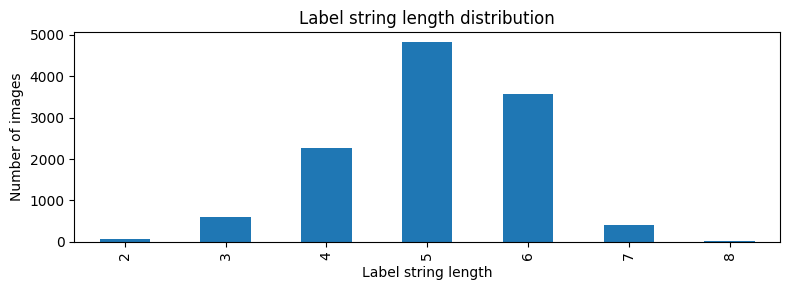

In [ ]:
df["label_length"] = df["label"].str.len()
display(df['label_length'].value_counts())
display(df["label_length"].describe())
display(df.groupby(["source", "split"])["label_length"].describe())

df["label_length"].value_counts().sort_index().plot(
    kind="bar", figsize=(8, 3), title="Label string length distribution"
)
plt.xlabel("Label string length")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

**Label Characteristics**
- Ground truth contains strings of digits ranging from 2 to 8 characters in length.
- The average string length is approximately 5.07 digits, and the median is 5.
- CAR-A has an average string length of approximately 4.52, while CAR-B is approximately 5.60.
- The distribution of string lengths between Train and Test is relatively similar across both datasets.
- The model needs to support recognizing strings of varying length.

,count
0,20348
1,6489
2,5323
3,4490
4,4272
5,5055
6,3606
7,3297
8,3419
9,3096


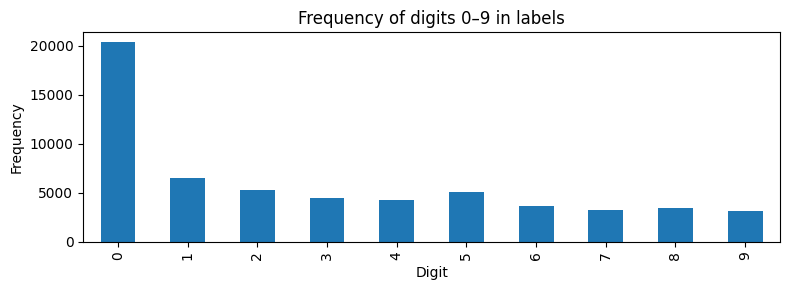

In [ ]:
digit_counts = pd.Series(
    [digit for label in df["label"] for digit in label]
).value_counts().reindex(list("0123456789"), fill_value=0)

display(digit_counts.rename("count").to_frame())

digit_counts.plot(kind="bar", figsize=(8, 3), title="Frequency of digits 0–9 in labels")
plt.xlabel("Digit")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Digit Distribution**
- Digits from 0 to 9 all appear in the dataset.
- The frequency of appearance among digits is uneven.
- The digit 0 appears most frequently (20,348 times), accounting for approximately 34.26% of the total digits.
- The digit 9 appears least frequently (3,096 times), accounting for approximately 5.21%.
- The individual digit recognition performance needs to be monitored to assess the impact of this data imbalance.

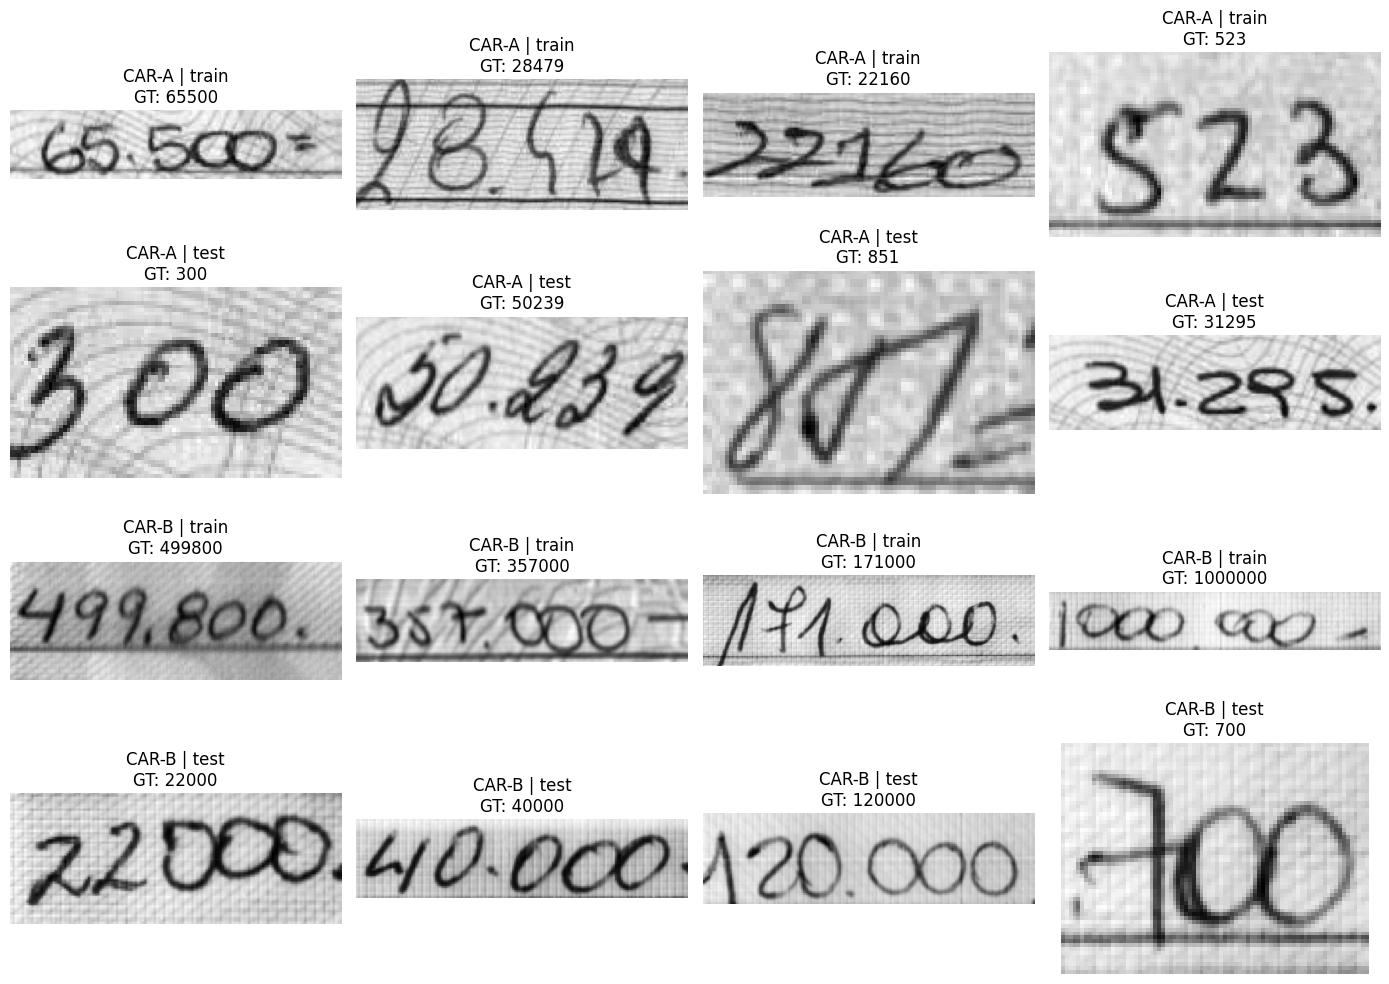

In [39]:
fig, axes = plt.subplots(4, 4, figsize=(14, 10))

groups = [
    ("CAR-A", "train"),
    ("CAR-A", "test"),
    ("CAR-B", "train"),
    ("CAR-B", "test")
]

for i, (source, split) in enumerate(groups):
    samples = df[
        (df["source"] == source) &
        (df["split"] == split)
    ].sample(4, random_state=42)

    for j, (_, row) in enumerate(samples.iterrows()):
        ax = axes[i, j]

        image = Image.open(row["image_path"]).convert("L")
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{source} | {split}\nGT: {row['label']}")
        ax.axis("off")

plt.tight_layout()
plt.show()

- **Handwriting variation:** The numerals have different handwriting styles, slant, and shapes between samples.
- **Background noise:** Some images have backgrounds with textured paper, lines, or outlines from bank forms.
- **Stroke variation:** The boldness and thickness of the handwriting are inconsistent.
- **Digit spacing:** The spacing between numerals varies; some numerals are quite close together.
- **Additional marks:** Images may contain dots, commas, lines, or other symbols in addition to the numerals in the ground truth.

In [40]:
# Labels are not just numbers
invalid_labels = df[~df["label"].str.fullmatch(r"\d+")]
print("Invalid label number:", len(invalid_labels))
display(invalid_labels.head())

# Duplicate image content: compare SHA-256 codes
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

df["image_hash"] = df["image_path"].map(file_hash)
duplicates = df[df.duplicated("image_hash", keep=False)]

print("Number of duplicate image lines:", len(duplicates))
pd.set_option("display.max_colwidth", None)
display(duplicates[["image_path", "label", "source", "split"]])

Invalid label number: 0


,image_path,label,source,split,width,height,mode,aspect_ratio,label_length


Number of duplicate image lines: 6


,image_path,label,source,split
1620,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_008620.png,145507,CAR-A,test
1628,..\data\raw\ORAND-CAR-2014\CAR-A\a_test_images\a_car_008628.png,145507,CAR-A,test
7742,..\data\raw\ORAND-CAR-2014\CAR-B\b_test_images\b_car_011517.png,40000,CAR-B,test
7743,..\data\raw\ORAND-CAR-2014\CAR-B\b_test_images\b_car_011518.png,40000,CAR-B,test
10346,..\data\raw\ORAND-CAR-2014\CAR-B\b_train_images\b_car_004863.png,403590,CAR-B,train
10347,..\data\raw\ORAND-CAR-2014\CAR-B\b_train_images\b_car_004864.png,403590,CAR-B,train


**Data Quality**
- All 11,719 images were read and matched with ground truth.
- No empty labels or labels containing characters other than alphanumeric characters were detected.
- Three pairs of images with duplicate content were detected using SHA-256.

In [41]:
# Remove duplicate images, keeping only 1 image per group
df = df.drop_duplicates(subset="image_hash", keep="first").copy()
print("Number of images after removing duplicates:", len(df))
print("Number of images removed:", 11719 - len(df))

# Save metadata for use in notebook preprocessing/model
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df.drop(columns=["split", "image_hash"]).to_csv(
    OUTPUT_DIR / "orand_car_metadata.csv", index=False
)
print("Saved:", (OUTPUT_DIR / "orand_car_metadata.csv").resolve())
print(df.info())

Number of images after removing duplicates: 11716
Number of images removed: 3
Saved: C:\Users\Admin\dl-seqforecast\data\processed\orand_car_metadata.csv
<class 'pandas.DataFrame'>
Index: 11716 entries, 0 to 11718
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   image_path    11716 non-null  str    
 1   label         11716 non-null  str    
 2   source        11716 non-null  str    
 3   split         11716 non-null  str    
 4   width         11716 non-null  int64  
 5   height        11716 non-null  int64  
 6   mode          11716 non-null  str    
 7   aspect_ratio  11716 non-null  float64
 8   label_length  11716 non-null  int64  
 9   image_hash    11716 non-null  str    
dtypes: float64(1), int64(3), str(6)
memory usage: 1006.8 KB
None
